# 04 · Team shape and transitions

What the tracking says about structure, and what changes in the eight seconds after a turnover.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import DERIVED_DIR, PROCESSED_DIR, PALETTE
plt.style.use("dark_background")
plt.rcParams.update({
    "figure.facecolor": PALETTE["surface"], "axes.facecolor": PALETTE["surface"],
    "savefig.facecolor": PALETTE["surface"], "grid.color": PALETTE["grid"],
    "axes.edgecolor": PALETTE["line"], "text.color": PALETTE["text"],
    "axes.labelcolor": PALETTE["text_secondary"], "xtick.color": PALETTE["muted"],
    "ytick.color": PALETTE["muted"], "font.size": 9, "figure.dpi": 110,
})
pd.set_option("display.width", 140, "display.max_columns", 40)


In [2]:
tf = pd.read_parquet(DERIVED_DIR / "team_frames" / "1874553.parquet")
matches = pd.read_parquet(PROCESSED_DIR / "matches.parquet").set_index("match_id")
names = matches.loc[1874553]
tf["team"] = np.where(tf.team_id == names.home_team_id, names.home_team, names.away_team)
tf.groupby("team")[["width_m", "length_m", "compactness_m", "hull_area_m2",
                    "def_line_x", "att_line_x", "space_between_lines_m"]].mean().round(1)

,width_m,length_m,compactness_m,hull_area_m2,def_line_x,att_line_x,space_between_lines_m
team,,,,,,,
Adelaide United,41.8,32.3,15.5,922.2,-11.2,10.7,5.0
Brisbane FC,38.1,30.2,14.3,772.9,-15.7,4.9,6.3


## Lines through the match

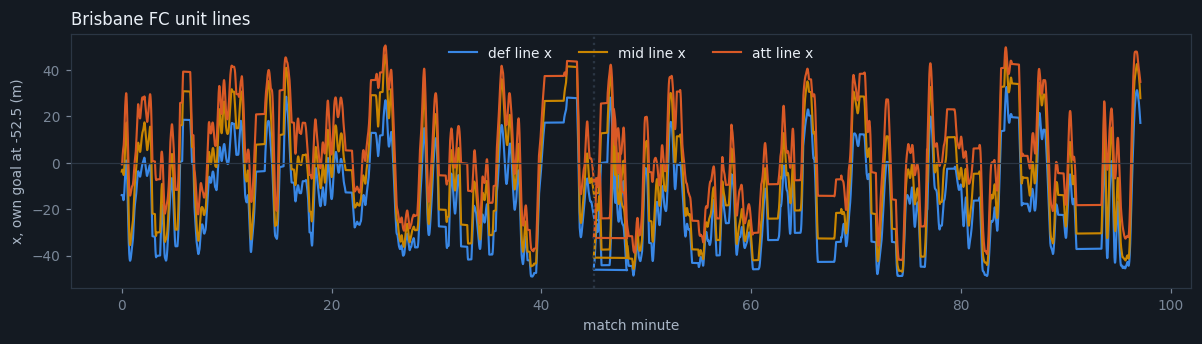

In [3]:
home = tf[tf.team == names.home_team].sort_values("frame")
sm = home.set_index(home.match_clock_s / 60)[["def_line_x", "mid_line_x", "att_line_x"]] \
        .rolling(150, min_periods=1).mean()
plt.figure(figsize=(11, 3.2))
for c, col in zip(sm.columns, [PALETTE["accent"], PALETTE["accent3"], PALETTE["accent2"]]):
    plt.plot(sm.index, sm[c], lw=1.4, color=col, label=c.replace("_", " "))
plt.axvline(45, ls=":", color=PALETTE["line"]); plt.axhline(0, lw=0.8, color=PALETTE["line"])
plt.ylabel("x, own goal at -52.5 (m)"); plt.xlabel("match minute")
plt.title(f"{names.home_team} unit lines", loc="left"); plt.legend(frameon=False, ncol=3)
plt.tight_layout()

## Shape when the ball is lost

In [4]:
tr = pd.read_parquet(DERIVED_DIR / "transitions.parquet").dropna(
    subset=["loser_compactness_start_m"])
q = pd.qcut(tr.loser_compactness_start_m, 5,
            labels=["most compact", "Q2", "Q3", "Q4", "most stretched"])
out = tr.assign(quintile=q).groupby("quintile", observed=True).agg(
    n=("max_progress_m", "size"), compactness_m=("loser_compactness_start_m", "mean"),
    opp_progress_m=("max_progress_m", "mean"), opp_hold_s=("held_possession_s", "mean"))
out.round(2)

,n,compactness_m,opp_progress_m,opp_hold_s
quintile,,,,
most compact,1030,10.28,15.79,10.39
Q2,1029,13.24,15.93,10.99
Q3,1029,15.00,15.73,10.55
Q4,1029,16.85,15.03,8.66
most stretched,1029,19.50,12.62,7.15


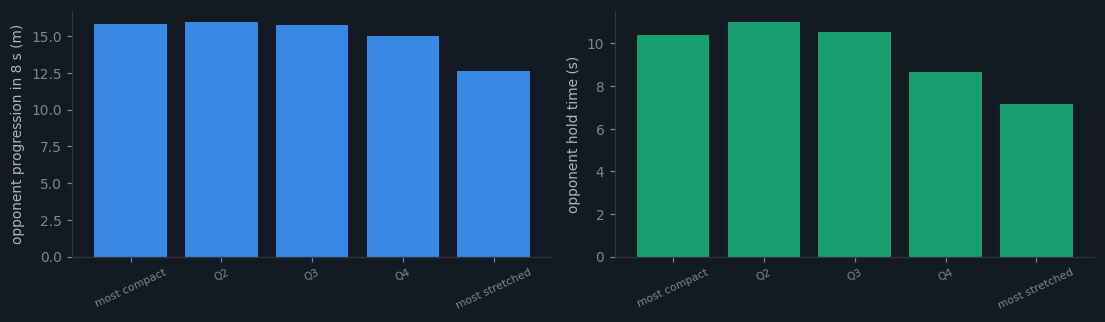

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].bar(range(5), out.opp_progress_m, color=PALETTE["accent"])
ax[0].set_ylabel("opponent progression in 8 s (m)")
ax[1].bar(range(5), out.opp_hold_s, color=PALETTE["good"])
ax[1].set_ylabel("opponent hold time (s)")
for a in ax:
    a.set_xticks(range(5)); a.set_xticklabels(out.index, rotation=25, fontsize=7)
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

Teams that lose the ball while stretched concede **less** progression and get
it back sooner. A stretched shape is mostly a team committed high up the pitch,
and the counter-press that follows shortens the opponent's possession. This is
an association across 5,147 turnovers, not a licence to leave gaps.